# Practical Lab — Building AI Agents with LangGraph

**Course:** Advanced Artificial Intelligence / Generative AI
**Attendees** PHD Students.
**Technology:** Python, LangChain, LangGraph, LLM APIs  
**Level:** Intermediate | **Format:** Jupyter Notebook

## 1. Lab objectives

At the end of this lab, you should be able to:

- Explain the difference between a conventional LLM chain and an agentic workflow.
- Understand the main LangGraph concepts: **State, Nodes, Edges, Conditional edges, Graph execution**.
- Build a simple conversational agent and add memory/state to it.
- Implement conditional routing and integrate tools.
- Build a multi-step research-style agent that can decide which action to perform.
- Visualize and test the resulting graph, and evaluate its behavior.

> **Tip:** Write your answers to the conceptual questions in the *"Your answer"* cells. They form part of your final report.

## PART I — Environment setup
### Exercise 1 — Install LangGraph

In [1]:
!pip install -U langgraph langchain langchain-openai langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 26.7 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.18
    Uninstalling langgraph-1.2.18:
      Successfully uninstalled langgraph-1.2.18
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [langchain-community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.19
LangChain: 1.4.7


### Question
What is the role of:
1. **LangChain?**
2. **LangGraph?**
3. **An LLM?**

**Your answer:**  
**1. LangChain**

LangChain is a toolbox for building applications on top of language models. It provides ready-made building blocks: prompt templates, connectors to different LLM providers, tools, document loaders and output parsers. These pieces can be linked together into a *chain*, where the output of one step becomes the input of the next. The path is usually fixed and runs in one direction, from start to end.

**2. LangGraph**

LangGraph is a library built on LangChain for creating *agents*, meaning applications where the model can decide what to do next. The workflow is described as a graph:

- **Nodes** are the steps (calling the model, using a tool).
- **Edges** connect the steps.
- A shared **State** keeps the information (messages, intermediate results) as the graph runs.

Unlike a simple chain, a graph can contain conditions and loops. The agent can call a tool, look at the result, and choose to continue or stop. LangGraph also handles memory between conversation turns.

**3. An LLM (Large Language Model)**

An LLM is the "brain" of the system. It is a neural network trained on very large amounts of text to predict the next words, which lets it understand instructions and generate answers. In an agent, the LLM reads the current situation, reasons about it and decides on the next action: answer directly, call a tool, or ask for more information. On its own, it cannot act in the outside world or remember past conversations. LangChain and LangGraph provide those capabilities around it.

**In short:** the LLM thinks, LangChain provides the building blocks, and LangGraph organizes those blocks into a workflow that can make decisions, loop and remember.

## PART II — First LangGraph workflow
### Exercise 2 — Understanding State

In LangGraph, the **state** represents the information shared between nodes.

In [3]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [4]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [5]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [6]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


**Expected result**
```python
{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}
```

### Questions
1. What is a node?
2. What is an edge?
3. What is `START`?
4. What is `END`?
5. Why is the state passed between nodes?

**Your answer:**  

**1. What is a node?**

A node is one step of the workflow. It is a Python function that receives the current state, does some work (for example calling an LLM or a tool), and returns the values to update in the state. In our example, `process` is a node: it reads `message` and writes `response`.

**2. What is an edge?**

An edge is a connection between two nodes. It defines the order of execution, meaning which node runs after the current one. In our example, the edges are `START → process` and `process → END`.

**3. What is `START`?**

`START` is a special entry point of the graph. It is not a real node that does work. It only indicates which node runs first when the graph is invoked.

**4. What is `END`?**

`END` is a special exit point of the graph. When execution reaches `END`, the graph stops and returns the final state.

**5. Why is the state passed between nodes?**

The state is the shared memory of the graph. Each node reads the information it needs from it and adds or updates its own results. Passing the state from node to node lets the steps cooperate without calling each other directly: each node only needs the state, not the other nodes. At the end, the state contains all the results. In our example, the final state holds both the original `message` and the `response` produced by the `process` node.

## PART III — Building an LLM Agent
### Exercise 3 — Connect an LLM

**Do not hard-code the API key in the notebook.** Prefer an environment variable configured outside the notebook; otherwise prompt for it securely as below.

In [8]:
import os
from getpass import getpass
from langchain_openai import ChatOpenAI

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")

llm = ChatOpenAI(
    model="gpt-4o-mini", # or other model
    temperature=0
)

print(llm.invoke("Say hello in one short sentence.").content)

OpenAIRateLimitError: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}

In [9]:
!pip install -q langchain-groq

import os
from getpass import getpass
from langchain_groq import ChatGroq

# Supprimer les anciennes clés en mémoire
os.environ.pop("OPENAI_API_KEY", None)
os.environ.pop("GROQ_API_KEY", None)

os.environ["GROQ_API_KEY"] = getpass("Enter your Groq API key: ")

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0
)

print(llm.invoke("Say hello in one short sentence.").content)

Enter your Groq API key: ··········


NotFoundError: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_request_error', 'code': 'model_not_found'}}

In [10]:
from groq import Groq

client = Groq()
for m in sorted(client.models.list().data, key=lambda x: x.id):
    print(m.id)

allam-2-7b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3
whisper-large-v3-turbo


In [11]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

print(llm.invoke("Say hello in one short sentence.").content)

Hello!


### Exercise 4 — Create an LLM node

In [12]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.content}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [13]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

Artificial intelligence (AI) is the field of computer science that creates systems capable of performing tasks that normally require human intelligence, such as learning, reasoning, perception, and decision‑making. These systems use algorithms—often based on statistical models, neural networks, or symbolic reasoning—to process data, recognize patterns, and improve their performance over time. By automating complex cognitive functions, AI enables applications ranging from voice assistants and medical diagnostics to autonomous vehicles and predictive analytics.


## PART IV — Multi-node AI workflow
### Exercise 5 — Build a two-stage agent

```
User question → Question analyzer → Answer generator → Final answer
```

In [14]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.content}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.content}

In [15]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [16]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

**Reinforcement Learning (RL)** is a branch of machine‑learning in which an **agent** learns to make a sequence of decisions by interacting with an **environment** and receiving feedback in the form of **rewards** (or penalties). The goal of the agent is to discover a **policy**—a mapping from observed states to actions—that maximizes the cumulative reward it obtains over time.

---

### Core Elements of an RL Problem  

| Element | What it is | Role in learning |
|---------|------------|------------------|
| **Agent** | The learner/decision‑maker (e.g., a robot, a software program). | Chooses actions based on its current policy. |
| **Environment** | Everything the agent interacts with (the world, a game, a simulator). | Supplies the current **state**, receives the agent’s action, and returns a **reward** and the next state. |
| **State (s)** | A representation of the environment at a given moment (e.g., position of a robot, board configuration). | Provides the information the agent u

### Observation

The workflow now has two LLM nodes executed in sequence: START → analyzer → answer → END.

- The **analyzer** node reads the question and writes into `analysis` the topic, the user's intention and the information needed.
- The **answer** node reads both `question` and `analysis` from the state and generates the final answer.

The state is what connects the two nodes: the second node uses the result of the first one without calling it directly. Compared with Exercise 4 (a single LLM call), splitting the task into "understand" then "answer" gives a more structured and complete response. For "What is reinforcement learning?", the answer covers the definition, the core elements (agent, environment, state, action, reward, policy), the exploration/exploitation trade-off, typical algorithms, a comparison with supervised and unsupervised learning, and a concrete example.


## PART V — Conditional routing

This is where LangGraph becomes particularly interesting. The agent decides which branch to follow:

```
                 ┌─── Mathematics
Question ────────┼─── Programming
                 └─── General AI
```

### Exercise 6 — Create a router

In [18]:
class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.content.strip().lower()}

### Exercise 7 — Create specialized nodes

In [19]:
def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.content}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.content}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.content}

## PART VI — Conditional edges

The routing function inspects the state and returns the **name of the next branch**.

In [20]:
def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"   # default / fallback branch

In [21]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [22]:
questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })
    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: The derivative of the function  

\[
f(x)=x^{2}
\]

with respect to \(x\) is found using the power rule for differentiation:

\[
\frac{d}{dx}\big[x^{n}\big] = n\,x^{\,n-1}.
\]

Here \(n = 2\). Applying the rule:

\[
\frac{d}{dx}\big[x^{2}\big] = 2\,x^{\,2-1} = 2x.
\]

\[
\boxed{\,\frac{d}{dx}(x^{2}) = 2x\,}
\]
QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: ## Creating a REST API with Python – A Step‑by‑Step Guide  

Below is a practical, end‑to‑end walkthrough that shows **how to build a production‑ready REST API** in Python.  
You’ll see two popular choices:

| Framework | When to use it | Highlights |
|-----------|----------------|------------|
| **FastAPI** | You want async support, automatic OpenAPI docs, type‑checked request/response models, and high performance. | Very little boilerplate, built‑in validation with **pydantic**, auto‑generated Swagger UI & ReDoc. |
| **Flask** (wi

### Observation

The graph is: START → classifier → (math | programming | ai) → END.

The classifier labels the question, then the routing function reads this label and chooses the next node. It looks for a keyword in the label, so routing still works if the LLM adds extra words; any unexpected label goes to the `ai` branch.

The three test questions were classified correctly and each was sent to the right node. The same LLM gives a different style of answer in each branch because each node has its own prompt.

Unlike Exercise 5, the path is not fixed: only one specialized node runs, chosen at run time from the state.

## PART VII — Agent with tools
### Exercise 8 — Create tools

The original lab uses `eval()`, which is **dangerous** (it can execute arbitrary Python). Below we first show the lab version for comparison, then a **safe** calculator built on `ast` that only allows arithmetic. We use the safe one from here on.

In [23]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [24]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [25]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Sunday, 01 November 2026, 15:34:41


### Observation

Three tools were created with the `@tool` decorator. The decorator turns a Python function into a tool the LLM can call: the function name, its arguments and its docstring are given to the model, so the docstring must clearly say when the tool should be used.

- `calculator_unsafe` uses `eval()`. It gives the right result (110), but it would execute any Python code sent by the model or the user, which is a security risk.
- `calculator` parses the expression with `ast` and only accepts numbers and arithmetic operators. It gives the same result (110) and rejects malicious input such as `__import__('os')` with "Invalid expression".
- `current_datetime` returns the current date and time. An LLM cannot know this on its own, which shows why tools are needed: they give the agent access to information and actions outside the model.

## PART VIII — Tool-using agent

```
                 ┌─────────────┐
Question → Agent ├→ Calculator │
                 └─────────────┘
                       ↓
                    Answer
```

The agent must **decide** whether it needs the calculator. Expected behavior for *"What is 125 * 38?"*:

`Agent → recognizes math problem → calls calculator → receives result → generates answer`

We bind the tools to the LLM, so it can emit *tool calls*. A conditional edge sends the flow to the `tools` node when a tool call is present, then loops back to the agent.

In [26]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime]
llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_builder = StateGraph(MessagesState)
tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)  # -> "tools" or END
tool_builder.add_edge("tools", "agent")                       # loop back with the result

tool_graph = tool_builder.compile()

In [27]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_baab41da-1930-47c6-881d-01acc1c5d8b6)
 Call ID: fc_baab41da-1930-47c6-881d-01acc1c5d8b6
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

125 × 38 = 4,750.
Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

The capital of Morocco is **Rabat**.


**Observe:** for the first question the trace contains an `AIMessage` with a tool call, a `ToolMessage` with the result, then the final answer. For the second question, no tool is called.

### Observation

The LLM itself decides whether a tool is needed. The graph is START → agent → (tools → agent)* → END.

- `bind_tools` gives the LLM the list of tools with their descriptions, so it can answer with a tool call instead of text.
- `tools_condition` checks the last message: if it contains a tool call, the flow goes to the `tools` node; otherwise it goes to END.
- `ToolNode` runs the requested tool and adds the result to the state as a `ToolMessage`. The edge `tools → agent` sends this result back to the LLM, which then writes the final answer.
- `MessagesState` keeps the whole conversation (human, AI and tool messages), so the agent sees the tool result in the next step.

Results:
- "What is 125 * 38?": the agent recognized a calculation and called `calculator` with `125 * 38`. The tool returned 4750, and the agent used it to answer "125 × 38 = 4,750". The trace shows four messages: Human, AI (tool call), Tool, AI (final answer).
- "What is the capital of Morocco?": the agent answered directly ("Rabat") without calling any tool, because general knowledge is enough.

Difference with Part VI: in Part VI the route was chosen by a separate classifier node with a fixed prompt. Here the LLM chooses the action itself, and the loop between `agent` and `tools` allows several tool calls if needed.

## PART IX — Memory
### Exercise 9 — Conversational state

The `add_messages` reducer **appends** new messages to the list instead of overwriting it.

In [28]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

**Without a checkpointer**, each `invoke` starts from scratch. **With a checkpointer** (`MemorySaver`) and a `thread_id`, the conversation persists between calls.

In [29]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

WITHOUT memory: I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!


In [30]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

Agent: Nice to meet you, Ahmed! How can I assist you today?
Agent: Your name is Ahmed.
Other thread: I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!


### Observation

Two mechanisms are needed for a conversational agent with memory:

- **The `add_messages` reducer** (in `Annotated[list, add_messages]`) tells LangGraph to append new messages to the list instead of replacing it. Within one execution, the history therefore grows: user message, then AI answer.
- **The checkpointer** (`MemorySaver`) saves the state at the end of each execution and reloads it at the next `invoke` with the same `thread_id`. Without it, the state is lost between calls.

Results:
- Without a checkpointer, the agent answered that it did not know the name: the second call started with an empty state and the LLM only saw "What is my name?".
- With `MemorySaver` and `thread_id = "ahmed-1"`, the agent answered "Your name is Ahmed": the first exchange was reloaded, so the LLM received the full conversation.
- With another `thread_id` ("someone-else"), the agent did not know the name: each thread has its own separate memory, like different users or conversations.


## Visualizing and testing graphs

`get_graph()` returns a drawable representation. If PNG rendering is unavailable (it may need network access), print the Mermaid source and paste it into <https://mermaid.live>.

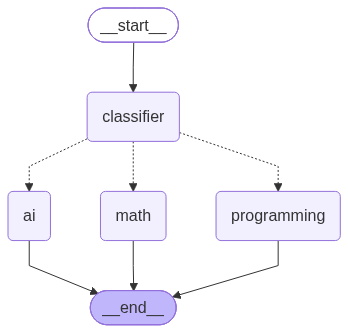

PNG rendering unavailable: Failed to reach https://mermaid.ink API while trying to render your graph. Status code: 400.

To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools<hr/><small><em>__tools = ['calculator', 'current_datetime']</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	tools --> agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [31]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

In [33]:
import html, re
from IPython.display import HTML, display

def show_graph_local(g):
    code = g.get_graph().draw_mermaid()
    code = re.sub(r"<hr/>.*?</small>", "", code)   # retire la liste des outils de l'étiquette
    code = html.escape(code)
    display(HTML(f"""
<pre class="mermaid">{code}</pre>
<script type="module">
  import mermaid from 'https://cdn.jsdelivr.net/npm/mermaid@10/dist/mermaid.esm.min.mjs';
  mermaid.initialize({{ startOnLoad: false }});
  await mermaid.run();
</script>
"""))

show_graph_local(router_graph)
show_graph_local(tool_graph)

**Observation**

The first display method uses the online service mermaid.ink to draw the graph as a PNG. It worked for the router graph but failed for the tool graph (error 400). The cause is the label of the `tools` node, which contains the list of tools (`['calculator', 'current_datetime']`): Mermaid cannot read these brackets and quotes.

To fix this, the Mermaid code was taken from `get_graph().draw_mermaid()`, the list of tools was removed from the label with a regular expression, and the graph was drawn directly in the notebook with Mermaid.js. Both graphs then displayed correctly:

- **Router graph**: the classifier leads to one of three branches (ai, math, programming), all ending at `__end__`.
- **Tool graph**: a loop `agent → tools → agent` that repeats until no tool is needed, then goes to `__end__`.

Solid arrows are fixed edges; dashed arrows are conditional edges.

## Evaluating the behavior of an agentic workflow

A minimal evaluation harness: define test cases with expected categories, run them, and compute accuracy. You can extend this with tool-call checks, latency, and cost.

In [34]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,1.08
1,Solve 2x + 3 = 11,mathematics,mathematics,True,1.16
2,How do I reverse a list in Python?,programming,programming,True,2.71
3,Write a function to check for palindromes.,programming,programming,True,3.54
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,6.67
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,5.92


Routing accuracy: 6/6 = 100%


**Discussion:** Where did the router fail (if anywhere)? What would make the routing more robust (structured output, few-shot examples, enum validation)?

**Your answer:**

**Where did the router fail?**

The router did not fail: all 6 questions were classified correctly (100% accuracy). This result must be read with caution:

- The test set is small and the questions are easy to classify, each clearly belonging to one category. Ambiguous questions would be a better test, for example "Write Python code to train a neural network" (programming or AI?) or "Compute the gradient of the loss function" (mathematics or AI?).
- The check `expected in got` is lenient: it accepts a label with extra words, so it measures whether the right keyword is present, not whether the output format is clean.
- The measured time covers the whole graph (classification + answer), not only the routing. Mathematics questions are the fastest (about 1 s) and AI questions the slowest (about 6 s), because the AI node asks for a long university-level answer.

**How to make the routing more robust**

- **Structured output**: use `llm.with_structured_output()` with a Pydantic model whose field is a `Literal["mathematics", "programming", "artificial_intelligence"]`. The model must then return one of the allowed values, and no text parsing is needed.
- **Enum validation with fallback**: check that the returned label belongs to the list of categories; if not, retry or send the question to a default branch, and log the case.
- **Few-shot examples**: add a few labeled examples to the classification prompt, especially borderline cases, so the model learns where the limits between categories are.
- **Clear category definitions**: describe each category in one sentence in the prompt, and state a priority rule for mixed questions.
- **Better evaluation**: a larger and more varied test set (ambiguous, multilingual, off-topic questions), several runs to check stability, and additional metrics such as confusion matrix, cost (tokens) and correct tool calls for the tool agent.

## PART X — Capstone project: Intelligent University Assistant

### Requirements covered below
| # | Requirement | Implementation |
|---|---|---|
| 1 | Question classifier | `classify` node → COURSES / PROGRAMMING / MATHEMATICS / ADMINISTRATION / GENERAL |
| 2 | Specialized agents | one node per category, built with `make_agent` |
| 3 | Memory | `MemorySaver` checkpointer + `thread_id` |
| 4 | Tools | `calculator`, `current_datetime` (+ optional extras) |
| 5 | Conditional routing | `route_after_classifier`, `route_after_agent`, `route_after_tools` |
| 6 | Error handling | empty input, unknown category, invalid tool calls, API errors |

### Architecture
```
User question → Classifier ─┬→ Courses Agent ──────┐
                            ├→ Programming Agent ──┤
                            ├→ Mathematics Agent ──┼→ Tool decision ─→ Tools (Calculator / Date-time / ...)
                            ├→ Administration Agent┤        │                │
                            ├→ General Agent ──────┘        ▼                │
                            └→ Fallback (empty/error)   Final response ◄─────┘
```
Each agent decides whether to call a tool; after the tool runs, control returns to the **same** agent, which writes the final response.

In [35]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

### 1. Classifier (with error handling)

In [36]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

### 2. Specialized agents (factory) + fallback node

In [37]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

### 3. Routing functions and graph assembly

`ToolNode(..., handle_tool_errors=True)` converts invalid tool calls / tool exceptions into error messages the agent can recover from, instead of crashing the graph.

In [38]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

PNG rendering unavailable: Failed to reach https://mermaid.ink API while trying to render your graph. Status code: 400.

To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classifier(classifier)
	fallback(fallback)
	tools(tools<hr/><small><em>__tools = ['calculator', 'current_datetime']</em></small>)
	courses_agent(courses_agent)
	programming_agent(programming_agent)
	mathematics_agent(mathematics_agent)
	administration_agent(administration_agent)
	general_agent(general_agent)
	__end__([<p>__end__</p>]):::last
	__start__ --> classifier;
	administration_agent -.-> __end__;
	administration_agent -.-> tools;
	classifier -.-> administ

In [39]:
show_graph_local(assistant)

**Observation**

The PNG rendering failed again because of the `tools` node label, so the graph was displayed with the same local Mermaid.js method (`show_graph_local`).

The diagram matches the planned architecture:
- `__start__ → classifier` is a fixed edge.
- The classifier leads (dashed arrows) to one of the five specialized agents (courses, programming, mathematics, administration, general) or to `fallback` for empty input or API errors.
- Each agent can either go to `tools` or finish at `__end__`.
- `tools` returns to the agent that requested the tool. This return is conditional: `route_after_tools` uses the `category` stored in the state.
- `fallback → __end__` is a fixed edge.

All agents share a single `tools` node, which keeps the graph simple: tools are defined once and reused by every agent. The many dashed arrows show that almost every transition is decided at run time from the state, which is what makes the assistant agentic.

### 4. Demonstration — at least 5 different user queries
Includes: all categories, both tools, memory, and error cases (empty input).

In [40]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

USER    : What topics are usually covered in a machine learning course?
CATEGORY: COURSES
ASSISTANT: Below is a typical outline of what you’ll find in an undergraduate‑ or early‑graduate‑level **Machine Learning (ML) course**.  The exact order and depth can vary by institution, but most programs cover the same core ideas and a handful of popular extensions.

---

## 1. Course Foundations & Prerequisites  

| Prerequisite | Why It Matters | Typical Minimum Grade / Experience |
|--------------|----------------|------------------------------------|
| **Linear Algebra** (vectors, matrices, eigen‑values, SVD) | Most ML algorithms are expressed in matrix form; gradient calculations rely on vector calculus. | 1‑year college course (e.g., *Linear Algebra* or *Matrix Methods*). |
| **Probability & Statistics** (distributions, expectation, Bayes rule, hypothesis testing) | Understanding data uncertainty, model likelihood, and evaluation metrics. | Introductory stats + probability (or a combined 

In [41]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

USER    : My name is Ahmed.
CATEGORY: GENERAL
ASSISTANT: Nice to meet you, Ahmed! How can I assist you today?
USER    : What is my name?
CATEGORY: GENERAL
ASSISTANT: Your name is Ahmed.


In [42]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_c78a8dad-6167-4189-b335-48369eec2582)
 Call ID: fc_c78a8dad-6167-4189-b335-48369eec2582
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

**Step‑by‑step calculation**

1. Add the numbers inside the parentheses:  
   \(15 + 27 = 42\).

2. Multiply the sum by 3:  
   \(42 \times 3 = 126\).

**Result:** \((15 + 27) \times 3 = 126\).


**Observation**

**Demonstration (6 queries).** Each query was routed to the expected category: COURSES, PROGRAMMING, MATHEMATICS, ADMINISTRATION, GENERAL, and EMPTY for the blank input. The empty question was stopped before any LLM call and handled by the `fallback` node with a clear message. Each specialized agent answered in the style defined by its system prompt: a detailed course outline, documented Python code, a short numerical result, an administrative procedure, and the current date.

**Tools.** The mathematics result (125 × 38 + 17 = 4,767) and the date (Sunday, November 1, 2026) are correct. The full trace of "(15 + 27) * 3" confirms the tool loop: the agent emits a tool call to `calculator`, the `tools` node returns 126 as a `ToolMessage`, and control returns to the same agent, which writes a step-by-step answer.

**Memory.** With the same `thread_id`, the assistant remembered the user's name from the previous turn ("Your name is Ahmed"), thanks to the `MemorySaver` checkpointer.

### 5. Optional extensions
Add one or more of: Wikipedia, web search, a database (e.g. SQLite with course data), a PDF reader, or weather. Implement each as a `@tool`, append it to the `tools` list **before** calling `llm.bind_tools(...)`, and rebuild the graph.

```python
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wiki = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
```

In [43]:
!pip install -q wikipedia

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [46]:
import sqlite3
import time
from langchain_community.utilities import WikipediaAPIWrapper

# --- Base de données des doctorants (données fictives) ---
conn = sqlite3.connect(":memory:", check_same_thread=False)
conn.execute("""CREATE TABLE phd_students (
    student_id TEXT, name TEXT, thesis_topic TEXT, supervisor TEXT,
    laboratory TEXT, year INTEGER, publications INTEGER, defense_date TEXT)""")
conn.executemany("INSERT INTO phd_students VALUES (?,?,?,?,?,?,?,?)", [
    ("PHD001", "Ahmed Benali",   "Deep learning for medical image segmentation",   "Prof. Alaoui",     "LIST",  3, 4, "2027-06-20"),
    ("PHD002", "Sara El Amrani", "Explainable AI for smart cities",                "Prof. Idrissi",    "LaSIT", 2, 2, "2028-01-15"),
    ("PHD003", "Youssef Tazi",   "Reinforcement learning for energy optimization", "Prof. Alaoui",     "LIST",  4, 6, "2026-12-10"),
    ("PHD004", "Imane Chraibi",  "NLP for Arabic dialects",                        "Prof. Benjelloun", "LaSIT", 1, 0, "Not scheduled"),
    ("PHD005", "Omar Fassi",     "Federated learning for healthcare data",         "Prof. Idrissi",    "LIST",  3, 3, "2027-09-30"),
])
conn.commit()

@tool
def phd_database(keyword: str) -> str:
    """Search the university PhD students database by student name, ID, thesis topic,
    supervisor or laboratory (e.g. 'Sara', 'PHD003', 'Prof. Alaoui', 'LIST', 'NLP').
    Returns ID, name, thesis topic, supervisor, laboratory, year, number of publications
    and defense date. Use 'all' to list every PhD student."""
    try:
        if keyword.strip().lower() == "all":
            rows = conn.execute("SELECT * FROM phd_students").fetchall()
        else:
            k = f"%{keyword.strip()}%"
            rows = conn.execute(
                """SELECT * FROM phd_students
                   WHERE name LIKE ? OR student_id LIKE ? OR thesis_topic LIKE ?
                      OR supervisor LIKE ? OR laboratory LIKE ?""",
                (k, k, k, k, k),
            ).fetchall()
        if not rows:
            return f"No PhD student found for '{keyword}'."
        return "\n".join(
            f"{i} | {n} | thesis: {t} | supervisor: {s} | lab: {l} | year {y} | "
            f"{p} publications | defense: {d}"
            for i, n, t, s, l, y, p, d in rows
        )
    except Exception as e:
        return f"Database error: {e}"

# --- Wikipedia avec nombre limité de tentatives ---
_wiki_api = WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=1500)

@tool
def wikipedia(query: str) -> str:
    """Search Wikipedia for factual information about people, places or concepts."""
    for attempt in range(2):
        try:
            return _wiki_api.run(query)
        except Exception:
            time.sleep(1)
    return ("Wikipedia is currently unavailable. Do not call this tool again: "
            "answer from your own knowledge and tell the user the source could not be checked.")

# --- Ajouter les outils et relier le LLM ---
tools = [calculator, current_datetime, phd_database, wikipedia]
llm_with_tools = llm.bind_tools(tools)

# --- Mettre à jour les prompts (sans doublon si la cellule est relancée) ---
PHD_HINT = (" Use the phd_database tool for any question about this university's PhD students, "
            "supervisors, laboratories or thesis defenses.")
WIKI_HINT = " Use the wikipedia tool for factual questions about people, places or concepts."
for c in ["COURSES", "ADMINISTRATION", "GENERAL"]:
    if PHD_HINT not in SYSTEM_PROMPTS[c]:
        SYSTEM_PROMPTS[c] += PHD_HINT
if WIKI_HINT not in SYSTEM_PROMPTS["GENERAL"]:
    SYSTEM_PROMPTS["GENERAL"] += WIKI_HINT

# --- Reconstruire le graphe ---
builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
print("Tools:", [t.name for t in tools])

Tools: ['calculator', 'current_datetime', 'phd_database', 'wikipedia']


In [47]:
def ask_trace(question, thread_id):
    r = assistant.invoke({"messages": [HumanMessage(content=question)]},
                         {"configurable": {"thread_id": thread_id}})
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", r["category"])
    for m in r["messages"]:
        if getattr(m, "tool_calls", None):
            print("  -> Tool call  :", [(t["name"], t["args"]) for t in m.tool_calls])
        if m.type == "tool":
            print("  -> Tool result:", m.name, "|", m.content[:200])
    print("ASSISTANT:", r["messages"][-1].content)

ask_trace("Who is the supervisor of Sara El Amrani and what is her thesis about?", "ext-1")
ask_trace("Which PhD students are supervised by Prof. Alaoui?", "ext-2")
ask_trace("How many publications do the PhD students of the LIST laboratory have in total?", "ext-3")
ask_trace("Who was Ibn Khaldun?", "ext-4")

USER    : Who is the supervisor of Sara El Amrani and what is her thesis about?
CATEGORY: GENERAL
  -> Tool call  : [('phd_database', {'keyword': 'Sara El Amrani'})]
  -> Tool result: phd_database | PHD002 | Sara El Amrani | thesis: Explainable AI for smart cities | supervisor: Prof. Idrissi | lab: LaSIT | year 2 | 2 publications | defense: 2028-01-15
ASSISTANT: Sara El Amrani is supervised by **Prof. Idrissi**.  
Her PhD thesis is titled **“Explainable AI for smart cities,”** focusing on developing transparent and interpretable artificial‑intelligence methods that can be applied to urban‑infrastructure and smart‑city applications.
USER    : Which PhD students are supervised by Prof. Alaoui?
CATEGORY: ADMINISTRATION
  -> Tool call  : [('phd_database', {'keyword': 'Prof. Alaoui'})]
  -> Tool result: phd_database | PHD001 | Ahmed Benali | thesis: Deep learning for medical image segmentation | supervisor: Prof. Alaoui | lab: LIST | year 3 | 4 publications | defense: 2027-06-20
PHD003 | Yo

**Observation - Optional extensions**

Two tools were added: `phd_database` (SQLite database of fictitious PhD students, with parameterized queries) and `wikipedia`.

**PhD database.** The three questions were answered correctly from the database: Sara El Amrani's supervisor and thesis, the students supervised by Prof. Alaoui, and the total number of publications of the LIST laboratory (13). The questions were classified as GENERAL or ADMINISTRATION, not COURSES, but the database was still used because the hint about `phd_database` was added to several system prompts. For the total, the agent added 4 + 6 + 3 itself instead of calling the calculator, because only the MATHEMATICS prompt requires the calculator. The result is correct, but tool use clearly depends on the instructions given to each agent.

**Wikipedia.** In the first run, the Wikipedia API returned 11 consecutive errors (`JSONDecodeError`, a problem on the external service side). `handle_tool_errors=True` prevented a crash, but the agent repeated the same call each time, wasting API calls and risking LangGraph's recursion limit. The tool was rewritten with at most 2 retries and a clear message asking the agent not to call it again. In the second run, Wikipedia was still unavailable, but the agent made a single call, then answered from its own knowledge and told the user that the source could not be checked.

Lesson: error handling must not only prevent crashes; it must also stop the agent from looping on a failing tool (limited retries, explicit error messages, `recursion_limit`) and keep the user informed.

## Deliverables checklist

- [ ] `langgraph_lab.ipynb` (this notebook, executed, with outputs)
- [ ] `README.md` (setup, how to run, design choices)
- [ ] Source code
- [ ] Architecture diagram (export from `show_graph(assistant)` or Mermaid)
- [ ] Screenshots showing execution
- [ ] Short report answering the conceptual questions